# Step 4b: A stronger model (v2)

Three upgrades over the Step 4 model, and an honest side-by-side comparison at the end:

1. **Transfer learning.** Instead of starting from random numbers, the encoder (the left half of the U-Net) is a **ResNet34** already trained on 1.2 million everyday photos (ImageNet). It already knows edges, textures and shapes, so it learns landslides faster and usually better.
2. **Robustness to new imagery.** During training each band is randomly brightened or dimmed a little. This teaches the model not to depend on exact pixel values, which helps with the domain-shift problem from Step 5. This notebook also saves the training data's **value distribution per band** (`band_quantiles.npy`), so the web app can match new imagery to it.
3. **Test-time augmentation (TTA).** Each patch is predicted four times (normal and flipped) and the results are averaged.

**Before running**, in a terminal tab (not the one running JupyterLab):
```
conda activate geoai
conda install -c conda-forge timm huggingface_hub safetensors -y
pip install --no-deps segmentation-models-pytorch
```
Then restart this notebook's kernel (**Kernel → Restart Kernel**) so it sees the new library.

Training is slower than Step 4: roughly 2–3 minutes per epoch on an M2, so about 45–60 minutes for 20 epochs. Keep the laptop plugged in and awake (`caffeinate -i` in a terminal tab helps).

In [1]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import time, json
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

ROOT = Path.home() / "geoai"
DATA_DIR = ROOT / "data" / "TrainData"

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("Training on:", device, "| segmentation_models_pytorch", smp.__version__)

torch.manual_seed(0)
np.random.seed(0)

Training on: mps | segmentation_models_pytorch 0.5.0


## Same split as Step 4
The validation patches must be exactly the same ones Step 4 used, or the comparison at the end wouldn't be fair. Same random seed, same 15%.

In [2]:
def read_h5(path):
    with h5py.File(path, "r") as f:
        return f[list(f.keys())[0]][:]

n = len(list((DATA_DIR / "img").glob("image_*.h5")))
ids = np.arange(1, n + 1)
np.random.default_rng(42).shuffle(ids)
n_val = int(0.15 * n)
val_ids, train_ids = ids[:n_val], ids[n_val:]
print(f"{len(train_ids)} training patches, {len(val_ids)} validation patches")

mean, std = np.load(ROOT / "band_stats.npy")
std = np.where(std < 1e-6, 1.0, std)

3230 training patches, 569 validation patches


## Save the training data's value distribution
For each of the 14 layers, this records the values at every percentile (0%, 1%, …, 100%) across 500 training patches. The web app uses it to reshape new satellite images so their values follow the same distribution the model learned from. This is called **quantile matching**.

In [3]:
rng = np.random.default_rng(0)
sample = rng.choice(train_ids, size=min(500, len(train_ids)), replace=False)
stack = np.stack([read_h5(DATA_DIR / "img" / f"image_{int(i)}.h5").astype(np.float32) for i in sample])
quantiles = np.stack([np.nanpercentile(stack[..., b], np.linspace(0, 100, 101)) for b in range(stack.shape[-1])])
np.save(ROOT / "band_quantiles.npy", quantiles.astype(np.float32))
print("Saved band_quantiles.npy with shape", quantiles.shape)
del stack

Saved band_quantiles.npy with shape (14, 101)


## Dataset with stronger augmentation
Same as Step 4 (rotations and flips), plus **photometric jitter**: each band is randomly scaled and shifted a little. Real satellite images vary with sun angle, haze and processing, and this teaches the model to cope.

In [4]:
class LandslideDataset(Dataset):
    def __init__(self, ids, augment=False):
        self.ids = ids
        self.augment = augment

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        i = int(self.ids[idx])
        img = read_h5(DATA_DIR / "img" / f"image_{i}.h5").astype(np.float32)
        mask = read_h5(DATA_DIR / "mask" / f"mask_{i}.h5").astype(np.float32)
        img = np.nan_to_num((img - mean) / std).astype(np.float32).transpose(2, 0, 1)

        if self.augment:
            k = np.random.randint(4)
            img, mask = np.rot90(img, k, axes=(1, 2)), np.rot90(mask, k)
            if np.random.rand() < 0.5:
                img, mask = img[:, :, ::-1], mask[:, ::-1]
            scale = np.random.normal(1.0, 0.08, size=(img.shape[0], 1, 1)).astype(np.float32)
            shift = np.random.normal(0.0, 0.08, size=(img.shape[0], 1, 1)).astype(np.float32)
            img = img * scale + shift

        return torch.from_numpy(np.ascontiguousarray(img)), torch.from_numpy(np.ascontiguousarray(mask))[None]

train_loader = DataLoader(LandslideDataset(train_ids, augment=True), batch_size=16, shuffle=True, num_workers=0)
val_loader = DataLoader(LandslideDataset(val_ids), batch_size=32, shuffle=False, num_workers=0)

pos = sum(read_h5(DATA_DIR / "mask" / f"mask_{int(i)}.h5").sum() for i in train_ids)
landslide_frac = pos / (len(train_ids) * 128 * 128)
pos_weight = float(min((1 - landslide_frac) / landslide_frac, 10.0))
print(f"Landslide pixels: {landslide_frac:.2%} | pos_weight {pos_weight:.1f}")

Landslide pixels: 2.31% | pos_weight 10.0


## The v2 model: U-Net with a pretrained ResNet34 encoder
`segmentation_models_pytorch` builds the U-Net for us. Satellite patches have 14 layers rather than 3 (red, green, blue), so the library adapts the encoder's first layer by reusing its pretrained colour filters across the extra layers.

In [5]:
ENCODER = "resnet34"
ENCODER_WEIGHTS = "imagenet"   # downloads ~85 MB of pretrained weights the first time

model = smp.Unet(encoder_name=ENCODER, encoder_weights=ENCODER_WEIGHTS, in_channels=14, classes=1).to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} million")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Parameters: 24.5 million


## Loss, metrics and test-time augmentation
Same loss and metrics as Step 4. `predict` can optionally average four flipped versions of each patch (TTA).

In [6]:
bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], device=device))

def dice_loss(logits, target, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * target).sum(dim=(1, 2, 3))
    union = p.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return (1 - (2 * inter + eps) / (union + eps)).mean()

def loss_fn(logits, target):
    return bce(logits, target) + dice_loss(logits, target)

def scores(tp, fp, fn):
    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    iou = tp / (tp + fp + fn + 1e-9)
    return dict(precision=precision, recall=recall, f1=f1, iou=iou)

FLIPS = [(), (3,), (2,), (2, 3)]

@torch.no_grad()
def predict(model, loader, tta=False):
    model.eval()
    probs, truths = [], []
    for x, y in loader:
        x = x.to(device)
        p = 0
        for dims in (FLIPS if tta else [()]):
            xi = torch.flip(x, dims) if dims else x
            pi = torch.sigmoid(model(xi))
            p = p + (torch.flip(pi, dims) if dims else pi)
        probs.append((p / (len(FLIPS) if tta else 1)).cpu().numpy())
        truths.append(y.numpy())
    return np.concatenate(probs), np.concatenate(truths)

def best_threshold(probs, truths):
    best = (0.5, scores(0, 0, 0))
    for t in np.arange(0.1, 0.91, 0.05):
        pred = probs > t
        s = scores(float((pred & (truths == 1)).sum()), float((pred & (truths == 0)).sum()),
                   float((~pred & (truths == 1)).sum()))
        if s["f1"] > best[1]["f1"]:
            best = (round(float(t), 2), s)
    return best

## Train
Saved whenever validation F1 improves, to `~/geoai/landslide_unet_v2.pt`. For a quick test run, set `EPOCHS = 2`.

   epoch 1: batch 50/202 (20s)
   epoch 1: batch 100/202 (33s)
   epoch 1: batch 150/202 (46s)
   epoch 1: batch 200/202 (58s)
Epoch  1/20 | train loss 1.366 | F1 0.534 | IoU 0.364 | 64s  <- best so far, saved
   epoch 2: batch 50/202 (13s)
   epoch 2: batch 100/202 (26s)
   epoch 2: batch 150/202 (38s)
   epoch 2: batch 200/202 (50s)
Epoch  2/20 | train loss 1.040 | F1 0.525 | IoU 0.356 | 54s
   epoch 3: batch 50/202 (12s)
   epoch 3: batch 100/202 (24s)
   epoch 3: batch 150/202 (37s)
   epoch 3: batch 200/202 (49s)
Epoch  3/20 | train loss 0.941 | F1 0.570 | IoU 0.398 | 53s  <- best so far, saved
   epoch 4: batch 50/202 (12s)
   epoch 4: batch 100/202 (24s)
   epoch 4: batch 150/202 (36s)
   epoch 4: batch 200/202 (48s)
Epoch  4/20 | train loss 0.881 | F1 0.598 | IoU 0.427 | 52s  <- best so far, saved
   epoch 5: batch 50/202 (12s)
   epoch 5: batch 100/202 (24s)
   epoch 5: batch 150/202 (36s)
   epoch 5: batch 200/202 (48s)
Epoch  5/20 | train loss 0.837 | F1 0.517 | IoU 0.348 | 

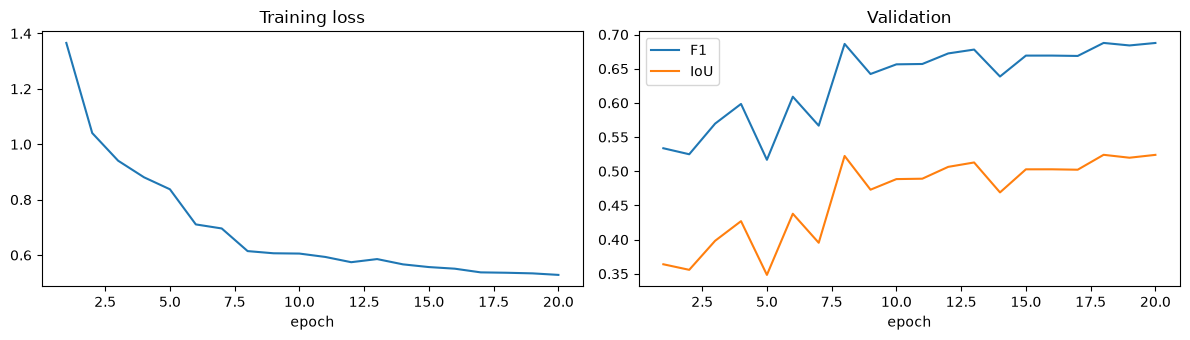

In [7]:
EPOCHS = 20

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
MODEL_PATH = ROOT / "landslide_unet_v2.pt"

history, best_f1 = [], -1.0
n_batches = len(train_loader)
for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, running, seen = time.time(), 0.0, 0
    for b, (x, y) in enumerate(train_loader, 1):
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(x)
        seen += len(x)
        if b % 50 == 0:
            print(f"   epoch {epoch}: batch {b}/{n_batches} ({time.time() - t0:.0f}s)", flush=True)
    scheduler.step()

    probs, truths = predict(model, val_loader)
    pred = probs > 0.5
    val = scores(float((pred & (truths == 1)).sum()), float((pred & (truths == 0)).sum()), float((~pred & (truths == 1)).sum()))
    history.append(dict(epoch=epoch, train_loss=running / seen, **val))
    note = ""
    if val["f1"] > best_f1:
        best_f1 = val["f1"]
        torch.save(model.state_dict(), MODEL_PATH)
        note = "  <- best so far, saved"
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {running / seen:.3f} | F1 {val['f1']:.3f} | IoU {val['iou']:.3f} "
          f"| {time.time() - t0:.0f}s{note}", flush=True)

print(f"\nBest validation F1 (threshold 0.5, no TTA): {best_f1:.3f}")

ep = [h["epoch"] for h in history]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.5))
a1.plot(ep, [h["train_loss"] for h in history]); a1.set_title("Training loss"); a1.set_xlabel("epoch")
a2.plot(ep, [h["f1"] for h in history], label="F1"); a2.plot(ep, [h["iou"] for h in history], label="IoU")
a2.set_title("Validation"); a2.set_xlabel("epoch"); a2.legend()
plt.tight_layout(); plt.show()

## Side-by-side: v1 vs v2, with and without TTA
Every model gets its own best threshold, and all four use the same validation patches. This table is the main result to report.

model TTA    thresh  precision   recall      F1     IoU
v1    no       0.75      0.718    0.762   0.739   0.586
v1    yes      0.70      0.705    0.780   0.741   0.588
v2    no       0.85      0.723    0.753   0.738   0.584
v2    yes      0.85      0.739    0.746   0.742   0.590


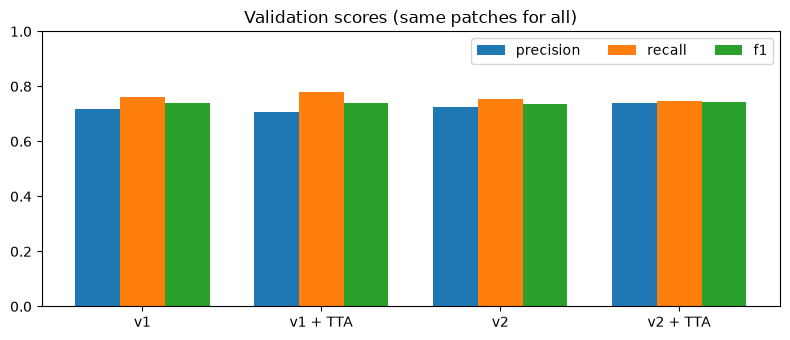

In [8]:
def double_conv(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
    )

class UNet(nn.Module):   # the Step 4 model, needed to load landslide_unet.pt
    def __init__(self, in_ch=14, base=32):
        super().__init__()
        c1, c2, c3, c4, c5 = base, base * 2, base * 4, base * 8, base * 16
        self.pool = nn.MaxPool2d(2)
        self.enc1, self.enc2 = double_conv(in_ch, c1), double_conv(c1, c2)
        self.enc3, self.enc4 = double_conv(c2, c3), double_conv(c3, c4)
        self.bottleneck = double_conv(c4, c5)
        self.up4, self.dec4 = nn.ConvTranspose2d(c5, c4, 2, stride=2), double_conv(c5, c4)
        self.up3, self.dec3 = nn.ConvTranspose2d(c4, c3, 2, stride=2), double_conv(c4, c3)
        self.up2, self.dec2 = nn.ConvTranspose2d(c3, c2, 2, stride=2), double_conv(c3, c2)
        self.up1, self.dec1 = nn.ConvTranspose2d(c2, c1, 2, stride=2), double_conv(c2, c1)
        self.head = nn.Conv2d(c1, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x); e2 = self.enc2(self.pool(e1)); e3 = self.enc3(self.pool(e2)); e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], 1)); d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1)); d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return self.head(d1)

v1_cfg = json.loads((ROOT / "model_config.json").read_text())
v1 = UNet(v1_cfg["in_channels"], v1_cfg["base"]).to(device)
v1.load_state_dict(torch.load(ROOT / "landslide_unet.pt", map_location=device))

model.load_state_dict(torch.load(MODEL_PATH, map_location=device))

results = {}
for name, m in [("v1", v1), ("v2", model)]:
    for tta in (False, True):
        probs, truths = predict(m, val_loader, tta=tta)
        t, s = best_threshold(probs, truths)
        results[(name, tta)] = dict(threshold=t, **s)
        if name == "v2":
            v2_probs = probs   # keep the last (TTA) predictions for the pictures below

print(f"{'model':<6}{'TTA':<6}{'thresh':>7}{'precision':>11}{'recall':>9}{'F1':>8}{'IoU':>8}")
for (name, tta), r in results.items():
    print(f"{name:<6}{'yes' if tta else 'no':<6}{r['threshold']:>7.2f}{r['precision']:>11.3f}{r['recall']:>9.3f}{r['f1']:>8.3f}{r['iou']:>8.3f}")

labels = [f"{n}{' + TTA' if t else ''}" for n, t in results]
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(labels))
for j, metric in enumerate(["precision", "recall", "f1"]):
    ax.bar(x + (j - 1) * 0.25, [r[metric] for r in results.values()], width=0.25, label=metric)
ax.set_xticks(x, labels); ax.set_ylim(0, 1); ax.legend(ncol=3); ax.set_title("Validation scores (same patches for all)")
plt.tight_layout(); plt.show()

## Save v2 for the web app
This writes `model_config_v2.json` and adds v1's flip-averaged score to `model_config.json`, so the two can be compared fairly. The web app finds both and uses **whichever scored higher** as its default. You can still pick either one under **Model and false-alarm filters**. If v2 didn't beat v1, that's a legitimate result to report too.

In [9]:
v1_cfg["val_f1_tta"] = round(results[("v1", True)]["f1"], 4)
(ROOT / "model_config.json").write_text(json.dumps(v1_cfg, indent=2))

r = results[("v2", True)]
config_v2 = {
    "arch": "smp_unet", "encoder": ENCODER, "in_channels": 14, "weights": MODEL_PATH.name,
    "threshold": r["threshold"], "val_f1": round(r["f1"], 4), "val_precision": round(r["precision"], 4),
    "val_recall": round(r["recall"], 4), "val_iou": round(r["iou"], 4), "tta": True,
}
(ROOT / "model_config_v2.json").write_text(json.dumps(config_v2, indent=2))
print(json.dumps(config_v2, indent=2))

r1 = results[("v1", True)]
print(f"\nWith flip averaging: v1 F1 {r1['f1']:.3f}  vs  v2 F1 {r['f1']:.3f}  ({r['f1'] - r1['f1']:+.3f})")
print("The web app will default to", "v2" if r["f1"] > r1["f1"] else "v1")

{
  "arch": "smp_unet",
  "encoder": "resnet34",
  "in_channels": 14,
  "weights": "landslide_unet_v2.pt",
  "threshold": 0.85,
  "val_f1": 0.7422,
  "val_precision": 0.7385,
  "val_recall": 0.7458,
  "val_iou": 0.59,
  "tta": true
}

With flip averaging: v1 F1 0.741  vs  v2 F1 0.742  (+0.002)
The web app will default to v2


## Where v2 does better or worse
Validation patches where the two models disagree the most. Use these as examples in your write-up.

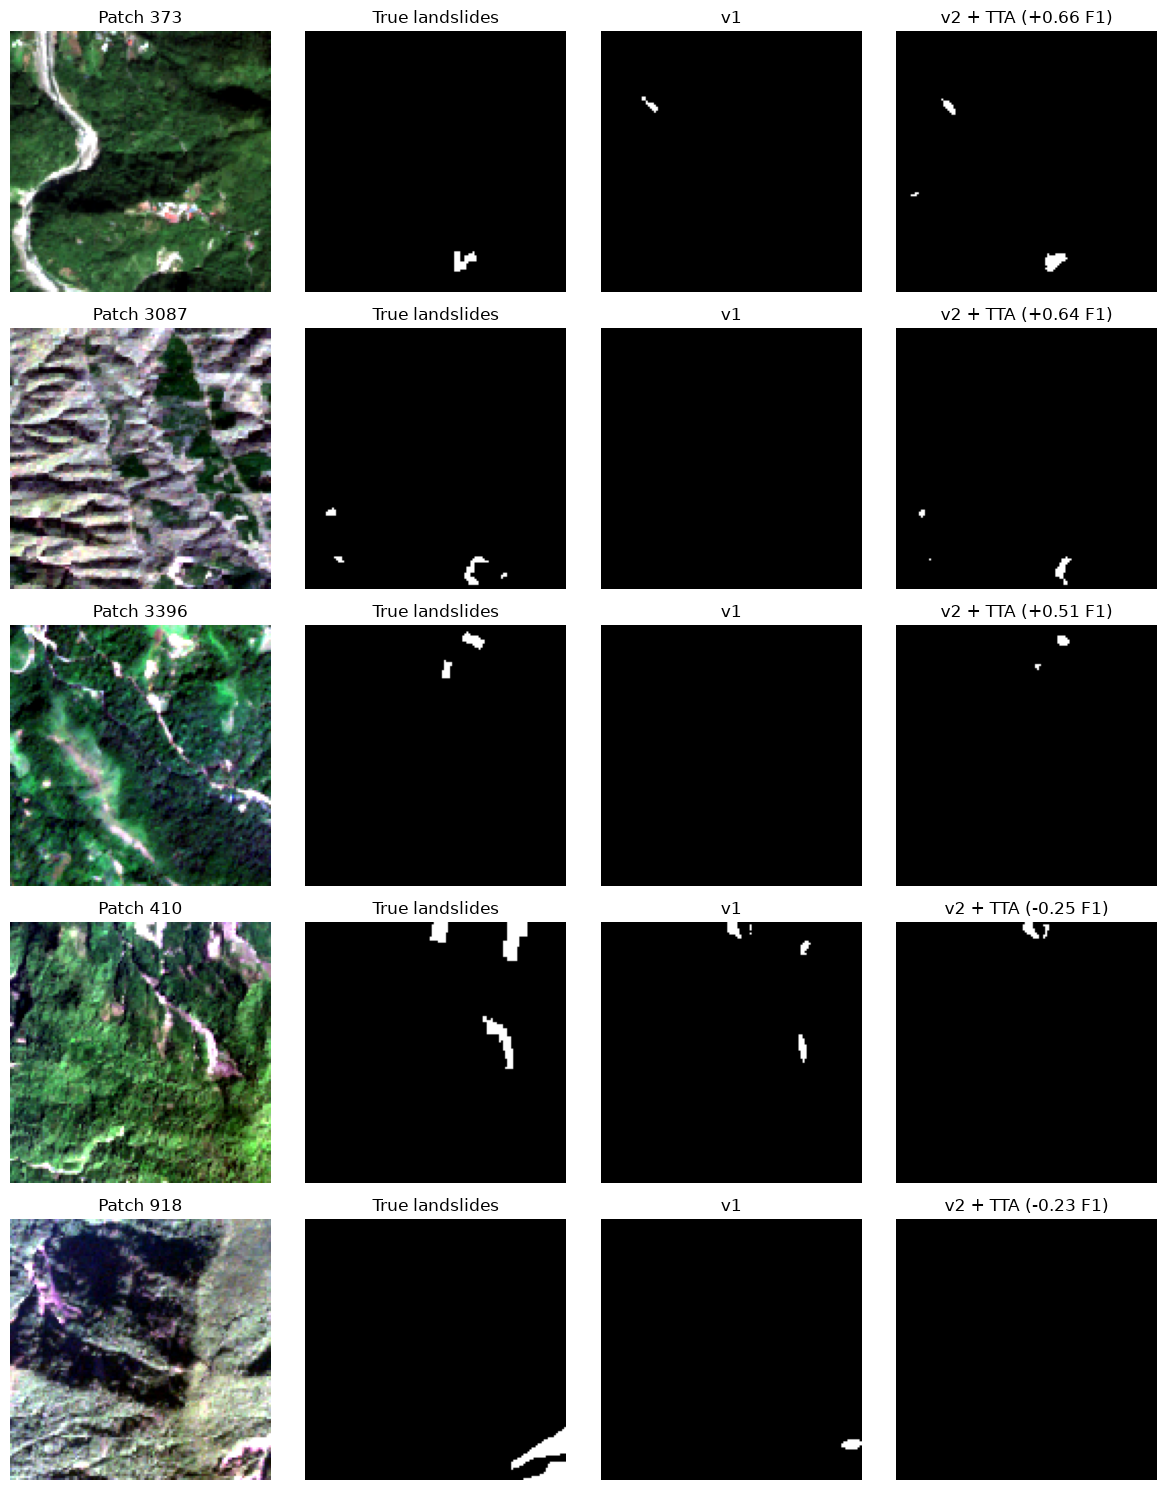

In [10]:
v1_probs, _ = predict(v1, val_loader, tta=False)
t1, t2 = results[("v1", False)]["threshold"], results[("v2", True)]["threshold"]
f1_per = lambda p, t: 2 * (p & (t == 1)).sum((1, 2, 3)) / (p.sum((1, 2, 3)) + (t == 1).sum((1, 2, 3)) + 1e-9)
has_ls = truths.sum((1, 2, 3)) > 50
gain = np.where(has_ls, f1_per(v2_probs > t2, truths) - f1_per(v1_probs > t1, truths), 0)
picks = list(np.argsort(gain)[::-1][:3]) + list(np.argsort(gain)[:2])

def true_color(i):
    raw = read_h5(DATA_DIR / "img" / f"image_{i}.h5").astype(np.float32)
    def s(a):
        lo, hi = np.percentile(a, (2, 98)); return np.clip((a - lo) / (hi - lo + 1e-6), 0, 1)
    return np.dstack([s(raw[:, :, b]) for b in (3, 2, 1)])

fig, axes = plt.subplots(len(picks), 4, figsize=(12, 3 * len(picks)))
for row, k in zip(axes, picks):
    i = int(val_ids[k])
    row[0].imshow(true_color(i)); row[0].set_title(f"Patch {i}")
    row[1].imshow(truths[k, 0], cmap="gray"); row[1].set_title("True landslides")
    row[2].imshow(v1_probs[k, 0] > t1, cmap="gray"); row[2].set_title("v1")
    row[3].imshow(v2_probs[k, 0] > t2, cmap="gray"); row[3].set_title(f"v2 + TTA ({gain[k]:+.2f} F1)")
    for ax in row: ax.axis("off")
plt.tight_layout(); plt.show()

## What to report
- The comparison table: v1 vs v2, with and without TTA, on the same validation patches.
- **Why** v2 helps: transfer learning gives the encoder a head start, and photometric jitter plus quantile matching target the domain-shift problem.
- One or two of the patches above where v2 clearly wins, and one where it doesn't.

Next: restart the web app (`Ctrl+C`, then `uvicorn app:app`). New runs will use the better model and quantile matching by default.